# E3: CNN | 64 Mel bins | có SpecAugment
Nhánh GitHub: `06-E3-cnn-mel64-specaug`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [1]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [2]:
EXP_ID = "E3"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'cnn', 'n_mels': 64, 'specaug': True}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [3]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E3 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7898


train:   0%|          | 0/40 [00:00<?, ?it/s]

E3 {'LR': 0.001, 'EPOCHS': 40} -> 0.7932


,LR,EPOCHS,val_macro_f1,best_epoch
1,0.0010,40,0.793225,38
0,0.0003,40,0.789757,39


E3: learning rate được chọn = 0.001


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [4]:
runs, rob = run_exp(EXP_ID, lr)

E3 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E3 | fold 1] acc 0.8225 | macro-F1 0.8124 | lr 0.001 | epoch tốt nhất 62 | 89s


E3 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E3 | fold 2] acc 0.8450 | macro-F1 0.8426 | lr 0.001 | epoch tốt nhất 72 | 89s


E3 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E3 | fold 3] acc 0.8475 | macro-F1 0.8431 | lr 0.001 | epoch tốt nhất 71 | 89s


E3 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E3 | fold 4] acc 0.8550 | macro-F1 0.8546 | lr 0.001 | epoch tốt nhất 70 | 89s


E3 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E3 | fold 5] acc 0.7875 | macro-F1 0.7699 | lr 0.001 | epoch tốt nhất 68 | 89s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.8225,0.8124,0.001,62,0.8414,89.4724
1,2,0.8450,0.8426,0.001,72,0.8515,89.4376
2,3,0.8475,0.8431,0.001,71,0.8808,89.1563
3,4,0.8550,0.8546,0.001,70,0.8077,89.4653
4,5,0.7875,0.7699,0.001,68,0.8371,89.5000


E3: Accuracy 83.15 ± 2.74 | Macro-F1 82.45 ± 3.43 | 1,185,490 tham số


,acc,macro_f1
condition,,
Sạch,83.15,82.45
20 dB,71.25,70.11
10 dB,44.35,45.38
0 dB,8.95,8.05


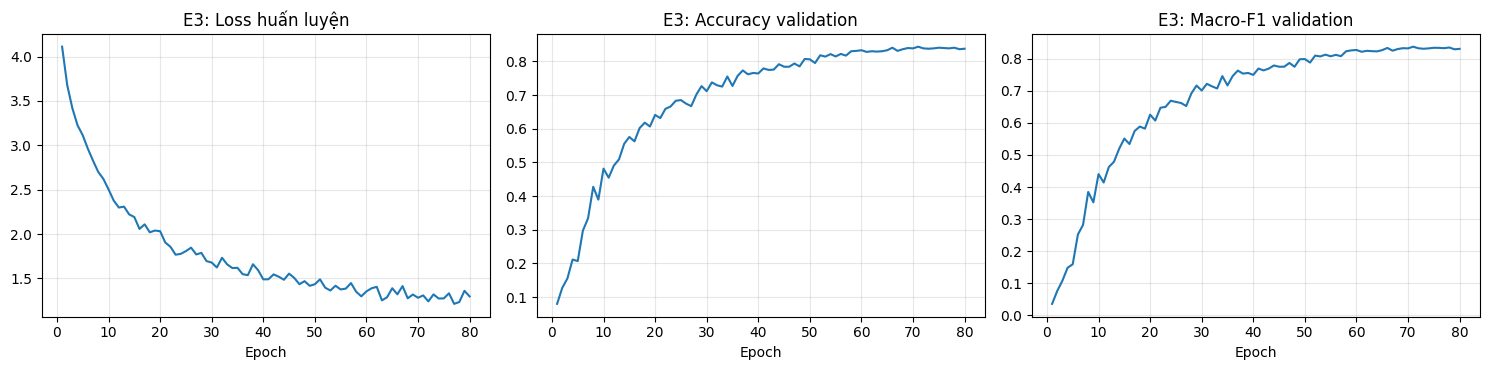

In [5]:
show_exp(EXP_ID)